# Forecasting Package: Choice-Based Conjoint Analysis Workbook

This notebook is designed for basic users working inside the `Forecasting_package` folder. The example data describes smartphone/product features such as brand, price, screen size, camera pixels, storage, folding capability, and battery life.

## Before You Start

The easiest way to run this notebook is with Anaconda, because Anaconda installs Python, Jupyter Notebook, and common data-analysis packages together.

Useful links:

- Download Anaconda: https://www.anaconda.com/download
- Anaconda installation guide: https://www.anaconda.com/docs/getting-started/anaconda/install
- Jupyter Notebook installation/help: https://jupyter.org/install

## How to Use This Forecasting Package

1. Keep this notebook and the CSV files together in the `Forecasting_package` folder.
2. Open Anaconda Navigator.
3. Launch Jupyter Notebook.
4. In Jupyter, open the `Forecasting_package` folder.
5. Open this notebook: `Forecasting_CBC_Workbook.ipynb`.
6. Run the cells from top to bottom.
7. Review the printed tables and the CSV/PNG files saved in the `outputs/` folder.

## Input Files Used in This Package

- `Feature_specs.csv`: lists each product feature, feature type, number of levels, and optional min/max values.
- `Feature_template.csv`: lists the actual levels for each feature.
- `Survey_response.csv`: contains participant responses in wide format, with columns such as `run_id_1`, `run_id_2`, and so on.

## What This Notebook Does

1. Generates a fractional factorial design and saves `fractional_factorial_design.csv`.
2. Saves `levels_used.csv`, which records all feature levels used by the model.
3. Uses the survey responses and generated design to fit a logistic-regression choice-based conjoint model.
4. Prints R2, p-values, significant features, coefficients, and the highest-probability product feature combination.
5. Creates visual summaries of feature-level coefficients, feature p-values, and top predicted combinations.

The notebook only imports common Python analysis packages. It does **not** import any custom local package.

## Cell 1: Import Packages

Run this cell first. These are common Python data-analysis and plotting packages used by this forecasting workbook.

If a package is missing, open a terminal in the `Forecasting_package` folder and run:

```bash
pip install -r requirements.txt
```

If you are using Anaconda, most packages may already be installed.

In [1]:
# Main analysis packages only. No custom project/package imports are used.
from dataclasses import dataclass
from difflib import SequenceMatcher
from pathlib import Path

import itertools
import math
import re

import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
from scipy.stats import chi2
from IPython.display import display


## Cell 2: File Locations and User Settings

Basic users usually only need to check this cell.

The notebook expects these files to be in the same `Forecasting_package` folder:

- `Feature_specs.csv`
- `Feature_template.csv`
- `Survey_response.csv`
- `fractional_factorial_design.csv`
- `levels_used.csv`

Important sample-data note: the included `Survey_response.csv` was created for the included 60-profile `fractional_factorial_design.csv`. For that reason, this notebook reuses and validates the included design by default.

Settings you may edit:

- `REGENERATE_FRACTIONAL_DESIGN = False`: recommended for running the sample package.
- `REGENERATE_FRACTIONAL_DESIGN = True`: use this only when starting a new study before collecting survey responses.
- `RUNS = None`: the notebook chooses a balanced number of design profiles automatically. With the current phone-feature example, this produces 60 profiles.
- `RUNS = 60`: use the same number of profiles as the sample survey response file.
- `ALPHA = 0.05`: p-values below 0.05 are treated as statistically significant.
- `TOP_N_COMBINATIONS = 10`: number of best predicted product combinations saved to CSV and plotted.

In [2]:
# This Forecasting_package folder should contain the notebook and these input CSV files:
# - Feature_specs.csv
# - Feature_template.csv
# - Survey_response.csv
# - fractional_factorial_design.csv
# - levels_used.csv
# - Forecasting_Model_Spec.csv
#
# In Jupyter, Path.cwd() is usually the folder where the notebook was opened.
# If a file is not found, make sure Jupyter is opened from the Forecasting_package folder.
BASE_DIR = Path.cwd()

# Input files for the product forecasting/conjoint example.
FEATURE_SPECS_PATH = BASE_DIR / "Feature_specs.csv"
FEATURE_TEMPLATE_PATH = BASE_DIR / "Feature_template.csv"
SURVEY_RESPONSE_PATH = BASE_DIR / "Survey_response.csv"
FORECASTING_MODEL_SPEC_PATH = BASE_DIR / "Forecasting_Model_Spec.csv"

# Fractional design files. The sample survey responses are linked to the included design.
FRACTIONAL_DESIGN_OUTPUT = BASE_DIR / "fractional_factorial_design.csv"
LEVELS_USED_OUTPUT = BASE_DIR / "levels_used.csv"

# Folder created by the conjoint analysis and graphing steps.
CONJOINT_OUTPUT_DIR = BASE_DIR / "outputs"
CONJOINT_OUTPUT_DIR.mkdir(exist_ok=True)

# Design/model settings.
REGENERATE_FRACTIONAL_DESIGN = False  # Keep False for the included sample responses.
RUNS = None                           # None means choose a practical balanced number of design profiles.
NUMERIC_CODING = "factor"             # "factor" estimates each numeric level; "linear" estimates one trend.
RANDOM_SEED = 42                      # Keeps newly generated designs reproducible.
ALPHA = 0.05                          # Significance threshold for p-values.
TOP_N_COMBINATIONS = 10               # Number of top predicted product combinations to save and plot.

print("Forecasting package folder:", BASE_DIR)
print("Design file:", FRACTIONAL_DESIGN_OUTPUT)
print("Levels file:", LEVELS_USED_OUTPUT)
print("Scenario forecast file:", FORECASTING_MODEL_SPEC_PATH)
print("Conjoint outputs folder:", CONJOINT_OUTPUT_DIR)
print("Regenerate fractional design:", REGENERATE_FRACTIONAL_DESIGN)


Forecasting package folder: /Users/semco/Documents/New project/Forecasting_package
Design file: /Users/semco/Documents/New project/Forecasting_package/fractional_factorial_design.csv
Levels file: /Users/semco/Documents/New project/Forecasting_package/levels_used.csv
Scenario forecast file: /Users/semco/Documents/New project/Forecasting_package/Forecasting_Model_Spec.csv
Conjoint outputs folder: /Users/semco/Documents/New project/Forecasting_package/outputs
Regenerate fractional design: False


## Cell 3: Load or Generate the Fractional Factorial Design

Run this cell after setting the file locations above.

This cell reads:

- `Feature_specs.csv`
- `Feature_template.csv`
- `fractional_factorial_design.csv` when `REGENERATE_FRACTIONAL_DESIGN = False`

It creates:

- `fractional_design_df`: a pandas DataFrame containing the selected product profiles.
- `fractional_factorial_design.csv`: the selected product profiles saved as a CSV file.
- `levels_used_df`: a summary of the levels used for each product feature.
- `levels_used.csv`: the same level summary saved as a CSV file.

For the included `Forecasting_package` sample, the notebook reuses and validates the existing 60-profile design because the sample `Survey_response.csv` refers to run IDs 1 through 60. If you are creating a new study before collecting responses, set `REGENERATE_FRACTIONAL_DESIGN = True`.

In [3]:
# -----------------------------
# Helper functions for the product fractional factorial design
# Basic users can run this full cell without editing the helper code.
# -----------------------------

CATEGORICAL_TYPES = {"categorical", "category", "nominal"}

SPEC_COLUMN_ALIASES = {
    "name": ("Features", "Parameter Name", "Feature", "Parameter"),
    "kind": ("Features_Type", "Parameter Type", "Feature Type", "Type"),
    "level_count": ("Level Number", "Levels", "Level Count", "Number of Levels"),
    "minimum": ("Minimum", "Min"),
    "maximum": ("Maximum", "Max"),
}


@dataclass(frozen=True)
class FeatureSpec:
    name: str
    kind: str
    level_count: int
    minimum: float | None
    maximum: float | None
    levels: tuple[str, ...]


def clean_header(value):
    return str(value).replace("\ufeff", "").strip()


def read_csv(path):
    df = pd.read_csv(path, encoding="utf-8-sig")
    df.columns = [clean_header(column) for column in df.columns]
    return df


def normalized_column_name(value):
    return re.sub(r"[^a-z0-9]+", "", clean_header(value).lower())


def resolve_spec_columns(specs_df):
    # Allows user-friendly column names such as Features/Features_Type.
    normalized_to_original = {
        normalized_column_name(column): column for column in specs_df.columns
    }
    resolved = {}
    missing = []

    for field_name, aliases in SPEC_COLUMN_ALIASES.items():
        matched_column = None
        for alias in aliases:
            normalized_alias = normalized_column_name(alias)
            if normalized_alias in normalized_to_original:
                matched_column = normalized_to_original[normalized_alias]
                break
        if matched_column is None:
            missing.append("/".join(aliases))
        else:
            resolved[field_name] = matched_column

    if missing:
        raise ValueError(
            f"Feature_specs.csv is missing required columns: {missing}. "
            f"Available columns: {list(specs_df.columns)}"
        )
    return resolved


def comparable_name(value):
    # Makes column matching tolerant of spaces, underscores, punctuation, and units.
    text = clean_header(value).lower()
    text = text.replace("dollars", "$" ).replace("dollar", "$")
    text = re.sub(r"[^a-z0-9]+", "", text)
    for suffix in ("usd", "days", "day"):
        if text.endswith(suffix):
            text = text[: -len(suffix)]
    return text


def match_template_column(feature_name, template_columns):
    target = comparable_name(feature_name)
    scored = []
    for column in template_columns:
        candidate = comparable_name(column)
        if target == candidate:
            score = 1.0
        elif target in candidate or candidate in target:
            score = 0.95
        else:
            score = SequenceMatcher(None, target, candidate).ratio()
        scored.append((score, column))

    best_score, best_column = max(scored, key=lambda item: item[0])
    if best_score < 0.62:
        raise ValueError(f"Could not match feature {feature_name!r} to a template column.")
    return best_column


def optional_float(value):
    if pd.isna(value) or str(value).strip() == "":
        return None
    return float(value)


def normalize_kind(value):
    text = clean_header(value).lower()
    if text in {"continuous", "numeric"}:
        return "continuous"
    if text in {"discrete", "integer"}:
        return "discrete"
    if text in CATEGORICAL_TYPES:
        return "categorical"
    raise ValueError(f"Unsupported feature type: {value!r}")


def normalize_level(value, feature_type):
    if pd.isna(value):
        return ""
    text = str(value).strip()
    if text == "":
        return ""
    if feature_type in {"continuous", "discrete"}:
        numeric = float(text)
        return str(int(numeric)) if numeric.is_integer() else str(round(numeric, 6))
    return text


def unique_nonblank_levels(values, feature_type):
    levels = []
    seen = set()
    for value in values.tolist():
        level = normalize_level(value, feature_type)
        if level == "" or level in seen:
            continue
        levels.append(level)
        seen.add(level)

    if feature_type in {"continuous", "discrete"}:
        levels = sorted(levels, key=float)
    return levels


def generated_numeric_levels(name, feature_type, level_count, minimum, maximum):
    if minimum is None or maximum is None:
        raise ValueError(
            f"{name!r} needs explicit template levels or Minimum/Maximum values."
        )

    values = np.linspace(minimum, maximum, level_count)
    if feature_type == "discrete":
        values = np.rint(values)

    levels = []
    for value in values.tolist():
        level = str(int(value)) if float(value).is_integer() else str(round(float(value), 6))
        if level not in levels:
            levels.append(level)

    if len(levels) != level_count:
        raise ValueError(
            f"{name!r} generated {len(levels)} unique levels, but expected {level_count}."
        )
    return levels


def load_feature_specs(specs_path, template_path, strict=True):
    specs_df = read_csv(specs_path)
    template_df = read_csv(template_path)
    columns = resolve_spec_columns(specs_df)

    specs = []
    summary_rows = []

    for _, row in specs_df.iterrows():
        name = clean_header(row[columns["name"]])
        feature_type = normalize_kind(row[columns["kind"]])
        level_count = int(row[columns["level_count"]])
        minimum = optional_float(row[columns["minimum"]])
        maximum = optional_float(row[columns["maximum"]])

        template_column = match_template_column(name, list(template_df.columns))
        levels = unique_nonblank_levels(template_df[template_column], feature_type)

        if len(levels) != level_count:
            if feature_type in {"continuous", "discrete"} and len(levels) < level_count and not strict:
                levels = generated_numeric_levels(name, feature_type, level_count, minimum, maximum)
            else:
                raise ValueError(
                    f"{name!r} has {len(levels)} levels in Feature_template.csv, "
                    f"but Feature_specs.csv says {level_count}."
                )

        spec = FeatureSpec(
            name=name,
            kind=feature_type,
            level_count=level_count,
            minimum=minimum,
            maximum=maximum,
            levels=tuple(levels),
        )
        specs.append(spec)
        summary_rows.append({
            "Parameter Name": name,
            "Parameter Type": feature_type,
            "Level Number": level_count,
            "Levels Used": " | ".join(levels),
        })

    return specs, pd.DataFrame(summary_rows)


def full_factorial(specs):
    names = [spec.name for spec in specs]
    level_lists = [spec.levels for spec in specs]
    return pd.DataFrame(itertools.product(*level_lists), columns=names)


def effect_code(series, levels):
    # Effect coding creates k - 1 model columns for a feature with k levels.
    reference = levels[-1]
    coded = {}
    for level in levels[:-1]:
        column_name = f"{series.name}={level}"
        coded[column_name] = np.where(
            series == level,
            1.0,
            np.where(series == reference, -1.0, 0.0),
        )
    return pd.DataFrame(coded, index=series.index)


def build_design_model_matrix(candidates, specs, numeric_coding="factor"):
    parts = [pd.Series(1.0, index=candidates.index, name="Intercept")]

    for spec in specs:
        if spec.kind in {"continuous", "discrete"} and numeric_coding == "linear":
            values = pd.to_numeric(candidates[spec.name]).astype(float)
            if np.isclose(values.min(), values.max()):
                coded = pd.Series(0.0, index=candidates.index, name=spec.name)
            else:
                coded = 2.0 * (values - values.min()) / (values.max() - values.min()) - 1.0
                coded.name = spec.name
            parts.append(coded)
        else:
            parts.append(effect_code(candidates[spec.name], spec.levels))

    return pd.concat(parts, axis=1).astype(float)


def logdet_information(selected_x):
    information = selected_x.T @ selected_x
    sign, value = np.linalg.slogdet(information)
    return float(value) if sign > 0 else -np.inf


def random_balanced_design(specs, n_runs, rng):
    """Create a balanced random design directly from feature levels."""
    design_columns = {}

    for spec in specs:
        base_repeats = n_runs // spec.level_count
        remainder = n_runs % spec.level_count
        values = []
        for level in spec.levels:
            values.extend([level] * base_repeats)
        if remainder:
            extra_levels = rng.choice(spec.levels, size=remainder, replace=False)
            values.extend(extra_levels.tolist())
        values = np.array(values, dtype=object)
        rng.shuffle(values)
        design_columns[spec.name] = values.tolist()

    return pd.DataFrame(design_columns)


def random_candidate_design(candidates, n_runs, rng):
    """Fallback design when exact balanced level counts are not possible."""
    return candidates.sample(n=n_runs, replace=False, random_state=int(rng.integers(0, 2**32 - 1))).reset_index(drop=True)


def score_design(design, specs, numeric_coding):
    x = build_design_model_matrix(design, specs, numeric_coding=numeric_coding).to_numpy(dtype=float)
    rank = int(np.linalg.matrix_rank(x))
    score = logdet_information(x)
    return rank, score


def default_run_count(n_candidates, n_terms, specs):
    # Prefer run counts that are divisible by each product feature's number of levels.
    minimum_runs = min(n_candidates, max(2 * n_terms, n_terms + 4))
    level_lcm = 1
    for spec in specs:
        level_lcm = math.lcm(level_lcm, spec.level_count)
    balanced_runs = math.ceil(minimum_runs / level_lcm) * level_lcm
    practical_limit = math.ceil(minimum_runs * 1.5)
    return balanced_runs if balanced_runs <= n_candidates and balanced_runs <= practical_limit else minimum_runs


def d_optimal_fraction(candidates, specs, n_runs, numeric_coding="factor", seed=42, starts=2000):
    """
    Fast balanced D-optimal search for the Forecasting_package notebook.

    The earlier exhaustive exchange search can be slow for large mixed-level
    product spaces. This function repeatedly creates balanced random designs,
    scores each design by log determinant, and keeps the best full-rank design.
    """
    full_model_matrix = build_design_model_matrix(candidates, specs, numeric_coding=numeric_coding)
    n_candidates, n_terms = full_model_matrix.shape

    if n_runs > n_candidates:
        raise ValueError(f"RUNS cannot be larger than the full factorial size ({n_candidates}).")
    if n_runs < n_terms:
        raise ValueError(f"RUNS must be at least {n_terms} to estimate the main-effects model.")

    if n_runs == n_candidates:
        design = candidates.copy().reset_index(drop=True)
        design.insert(0, "run_id", np.arange(1, len(design) + 1))
        return design

    rng = np.random.default_rng(seed)
    exact_balance_possible = all(n_runs % spec.level_count == 0 for spec in specs)
    best_design = None
    best_score = -np.inf
    best_rank = -1

    for _ in range(starts):
        if exact_balance_possible:
            trial_design = random_balanced_design(specs, n_runs, rng)
            # Duplicate profiles are not useful in this design table, so skip them.
            if trial_design.duplicated().any():
                continue
        else:
            trial_design = random_candidate_design(candidates, n_runs, rng)

        rank, score = score_design(trial_design, specs, numeric_coding)
        if score > best_score or (not np.isfinite(best_score) and rank > best_rank):
            best_design = trial_design
            best_score = score
            best_rank = rank

    if best_design is None or best_rank < n_terms:
        raise ValueError(
            "Could not find a full-rank fractional design. Increase RUNS or the number of random starts."
        )

    design = best_design.reset_index(drop=True)
    design.insert(0, "run_id", np.arange(1, len(design) + 1))
    return design


def validate_fractional_design(design_df, specs):
    """Check that an included design file matches the current product features and levels."""
    if "run_id" not in design_df.columns:
        raise ValueError("fractional_factorial_design.csv must contain a run_id column.")

    design_df = design_df.copy()
    design_df["run_id"] = pd.to_numeric(design_df["run_id"], errors="raise").astype(int)

    if design_df["run_id"].duplicated().any():
        raise ValueError("fractional_factorial_design.csv contains duplicate run_id values.")

    for spec in specs:
        if spec.name not in design_df.columns:
            raise ValueError(f"fractional_factorial_design.csv is missing feature column {spec.name!r}.")
        design_df[spec.name] = design_df[spec.name].map(lambda value, t=spec.kind: normalize_level(value, t))
        observed = set(design_df[spec.name].dropna().astype(str))
        expected = set(spec.levels)
        unknown = sorted(observed - expected)
        if unknown:
            raise ValueError(f"Design contains unknown levels for {spec.name!r}: {unknown}")

    return design_df.sort_values("run_id").reset_index(drop=True)


# -----------------------------
# Run the fractional factorial design for the Forecasting_package product features
# This part reads the input CSVs, validates/reuses the included sample design,
# or regenerates a new design when REGENERATE_FRACTIONAL_DESIGN is True.
# -----------------------------

feature_specs, levels_used_df = load_feature_specs(
    FEATURE_SPECS_PATH,
    FEATURE_TEMPLATE_PATH,
    strict=True,
)

full_factorial_df = full_factorial(feature_specs)
design_x = build_design_model_matrix(full_factorial_df, feature_specs, numeric_coding=NUMERIC_CODING)
n_terms = design_x.shape[1]
n_candidates = len(full_factorial_df)

if REGENERATE_FRACTIONAL_DESIGN:
    n_runs = RUNS if RUNS is not None else default_run_count(n_candidates, n_terms, feature_specs)
    fractional_design_df = d_optimal_fraction(
        candidates=full_factorial_df,
        specs=feature_specs,
        n_runs=n_runs,
        numeric_coding=NUMERIC_CODING,
        seed=RANDOM_SEED,
        starts=2000,
    )
    print("Generated a new fractional factorial design.")
else:
    if not FRACTIONAL_DESIGN_OUTPUT.exists():
        raise FileNotFoundError(
            f"{FRACTIONAL_DESIGN_OUTPUT} was not found. Set REGENERATE_FRACTIONAL_DESIGN = True "
            "to create a new design."
        )
    fractional_design_df = validate_fractional_design(read_csv(FRACTIONAL_DESIGN_OUTPUT), feature_specs)
    n_runs = len(fractional_design_df)
    print("Reused and validated the included fractional_factorial_design.csv.")

fractional_design_df.to_csv(FRACTIONAL_DESIGN_OUTPUT, index=False)
levels_used_df.to_csv(LEVELS_USED_OUTPUT, index=False)

print(f"Product features: {len(feature_specs)}")
print(f"Full factorial product profiles: {n_candidates}")
print(f"Main-effects terms including intercept: {n_terms}")
print(f"Fractional design profiles: {len(fractional_design_df)}")
print(f"Saved/validated design CSV at: {FRACTIONAL_DESIGN_OUTPUT}")
print(f"Saved levels CSV to: {LEVELS_USED_OUTPUT}")

display(levels_used_df)
display(fractional_design_df.head())

Reused and validated the included fractional_factorial_design.csv.
Product features: 7
Full factorial product profiles: 7680
Main-effects terms including intercept: 20
Fractional design profiles: 60
Saved/validated design CSV at: /Users/semco/Documents/New project/Forecasting_package/fractional_factorial_design.csv
Saved levels CSV to: /Users/semco/Documents/New project/Forecasting_package/levels_used.csv


,Parameter Name,Parameter Type,Level Number,Levels Used
0,Brand,categorical,5,Apple | Samsung | Google | Nothing | Others
1,Price_$,continuous,4,300 | 750 | 1000 | 1300
2,Screen_Size_inch,discrete,4,5 | 6.1 | 6.5 | 7
3,Camera_Pixel_MP,continuous,4,20 | 35 | 48 | 200
4,Storage_GB,discrete,4,128 | 256 | 512 | 1024
5,Folding,categorical,2,Yes | No
6,Battery life_Up_to_Days,continuous,3,1 | 3 | 5


,run_id,Brand,Price_$,Screen_Size_inch,Camera_Pixel_MP,Storage_GB,Folding,Battery life_Up_to_Days
0,1,Others,1000,6.1,48,1024,No,5
1,2,Nothing,1300,6.5,20,256,Yes,1
2,3,Nothing,300,6.1,200,128,Yes,1
3,4,Nothing,1000,7,20,256,No,5
4,5,Others,1000,6.5,200,128,Yes,5


## Cell 4: Choice-Based Conjoint Analysis

Run this cell after Cell 3 has created `fractional_factorial_design.csv` and `levels_used.csv`.

This cell reads:

- `Survey_response.csv`
- `fractional_factorial_design.csv`
- `levels_used.csv`

It then:

1. Structures a new model dataset with the binary response/outcome and all product feature levels.
2. Fits a logistic regression model.
3. Prints McFadden pseudo R2, the overall model p-value, and significant product features.
4. Prints coefficients for every feature and level.
5. Finds the product feature combination with the highest predicted probability.

Important note for beginners: logistic regression needs a reference level for each feature. This notebook uses the first level listed in `levels_used.csv` as the reference level. Reference levels appear in the coefficient table with coefficient `0`.

In [4]:
# -----------------------------
# Helper functions for product choice-based conjoint analysis
# Basic users can run this full cell without editing the helper code.
# -----------------------------

OUTCOME_COLUMN = "outcome"
RUN_ID_COLUMN = "run_id"


def safe_name(value):
    text = re.sub(r"[^A-Za-z0-9]+", "_", str(value).strip())
    return text.strip("_") or "value"


def indicator_name(feature, level):
    return f"{safe_name(feature)}__{safe_name(level)}"


def load_level_specs_from_csv(levels_path):
    levels_df = read_csv(levels_path)
    specs = []

    for _, row in levels_df.iterrows():
        feature = clean_header(row["Parameter Name"])
        feature_type = normalize_kind(row["Parameter Type"])
        levels = tuple(
            normalize_level(level, feature_type)
            for level in str(row["Levels Used"]).split("|")
            if str(level).strip() != ""
        )
        expected_count = int(row["Level Number"])
        if len(levels) != expected_count:
            raise ValueError(
                f"{feature!r} has {len(levels)} levels in levels_used.csv, "
                f"but Level Number says {expected_count}."
            )
        specs.append(FeatureSpec(feature, feature_type, expected_count, None, None, levels))

    return specs


def find_participant_column(responses_df):
    for candidate in ["Participant_ID", "participant_id", "Participant", "Respondent_ID"]:
        if candidate in responses_df.columns:
            return candidate
    return responses_df.columns[0]


def response_run_columns(responses_df):
    columns = [column for column in responses_df.columns if re.fullmatch(r"run_id_\d+", str(column))]
    if not columns:
        raise ValueError("Survey_response.csv must contain columns named run_id_1, run_id_2, etc.")
    return sorted(columns, key=lambda column: int(str(column).split("_")[-1]))


def build_model_dataset(responses_df, design_df, specs):
    participant_col = find_participant_column(responses_df)
    run_columns = response_run_columns(responses_df)

    long_responses = responses_df.melt(
        id_vars=[participant_col],
        value_vars=run_columns,
        var_name="response_column",
        value_name=OUTCOME_COLUMN,
    )
    long_responses[RUN_ID_COLUMN] = (
        long_responses["response_column"].str.extract(r"run_id_(\d+)", expand=False).astype(int)
    )
    long_responses = long_responses.drop(columns=["response_column"])
    long_responses[OUTCOME_COLUMN] = pd.to_numeric(long_responses[OUTCOME_COLUMN], errors="raise").astype(int)

    invalid_values = sorted(set(long_responses[OUTCOME_COLUMN]) - {0, 1})
    if invalid_values:
        raise ValueError(f"Outcome values must be 0/1 only. Found: {invalid_values}")

    design_df = design_df.copy()
    design_df[RUN_ID_COLUMN] = pd.to_numeric(design_df[RUN_ID_COLUMN], errors="raise").astype(int)

    feature_columns = [spec.name for spec in specs]
    for spec in specs:
        design_df[spec.name] = design_df[spec.name].map(lambda value, t=spec.kind: normalize_level(value, t))

    missing_run_ids = sorted(set(long_responses[RUN_ID_COLUMN]) - set(design_df[RUN_ID_COLUMN]))
    if missing_run_ids:
        raise ValueError(f"Survey responses refer to run IDs missing from the design: {missing_run_ids}")

    model_dataset = long_responses.merge(
        design_df[[RUN_ID_COLUMN, *feature_columns]],
        on=RUN_ID_COLUMN,
        how="left",
        validate="many_to_one",
    )
    model_dataset = model_dataset.sort_values([participant_col, RUN_ID_COLUMN]).reset_index(drop=True)
    return model_dataset, participant_col


def encode_for_logistic_regression(model_dataset, specs):
    encoded_df = model_dataset.copy()
    all_indicator_columns = []
    model_columns = []
    reference_levels = {}

    for spec in specs:
        reference_level = spec.levels[0]
        reference_levels[spec.name] = reference_level

        for index, level in enumerate(spec.levels):
            column = indicator_name(spec.name, level)
            encoded_df[column] = (encoded_df[spec.name].astype(str) == level).astype(int)
            all_indicator_columns.append(column)

            # The first level is the reference level, so it is not included in the regression matrix.
            if index > 0:
                model_columns.append(column)

    return encoded_df, all_indicator_columns, model_columns, reference_levels


def fit_logistic_regression(encoded_df, model_columns, participant_col):
    y = encoded_df[OUTCOME_COLUMN].astype(float)
    x = encoded_df[model_columns].astype(float)
    x = sm.add_constant(x, has_constant="add")

    model = sm.GLM(y, x, family=sm.families.Binomial())

    # Clustered standard errors account for repeated answers from the same participant.
    result = model.fit(
        maxiter=200,
        cov_type="cluster",
        cov_kwds={"groups": encoded_df[participant_col]},
    )

    null_x = pd.DataFrame({"const": np.ones(len(y))}, index=encoded_df.index)
    null_result = sm.GLM(y, null_x, family=sm.families.Binomial()).fit(maxiter=200)
    return result, null_result


def make_metrics_table(result, null_result, model_dataset, participant_col, n_features):
    log_likelihood = float(result.llf)
    null_log_likelihood = float(null_result.llf)
    lr_chi_square = 2.0 * (log_likelihood - null_log_likelihood)
    lr_df = int(result.df_model)
    lr_p_value = float(chi2.sf(lr_chi_square, lr_df))
    pseudo_r2 = float(1.0 - (log_likelihood / null_log_likelihood))

    return pd.DataFrame([{
        "n_observations": len(model_dataset),
        "n_participants": model_dataset[participant_col].nunique(),
        "n_profiles": model_dataset[RUN_ID_COLUMN].nunique(),
        "n_features": n_features,
        "positive_outcomes": int(model_dataset[OUTCOME_COLUMN].sum()),
        "positive_rate": float(model_dataset[OUTCOME_COLUMN].mean()),
        "log_likelihood": log_likelihood,
        "null_log_likelihood": null_log_likelihood,
        "likelihood_ratio_chi_square": lr_chi_square,
        "likelihood_ratio_df": lr_df,
        "likelihood_ratio_p_value": lr_p_value,
        "mcfadden_pseudo_r2": pseudo_r2,
        "aic": float(result.aic),
        "bic": float(getattr(result, "bic_llf", result.bic)),
    }])


def make_coefficient_table(result, specs, reference_levels, alpha=0.05):
    conf_int = result.conf_int(alpha=alpha)
    rows = []

    for spec in specs:
        reference_level = reference_levels[spec.name]
        for level in spec.levels:
            column = indicator_name(spec.name, level)
            is_reference = level == reference_level

            if is_reference:
                coefficient = 0.0
                std_error = np.nan
                z_value = np.nan
                p_value = np.nan
                ci_lower = np.nan
                ci_upper = np.nan
            else:
                coefficient = float(result.params[column])
                std_error = float(result.bse[column])
                z_value = float(result.tvalues[column])
                p_value = float(result.pvalues[column])
                ci_lower = float(conf_int.loc[column, 0])
                ci_upper = float(conf_int.loc[column, 1])

            rows.append({
                "feature": spec.name,
                "level": level,
                "reference_level": reference_level,
                "is_reference": is_reference,
                "coefficient": coefficient,
                "std_error": std_error,
                "z_value": z_value,
                "p_value": p_value,
                "odds_ratio": float(np.exp(coefficient)),
                "ci_lower": ci_lower,
                "ci_upper": ci_upper,
                "odds_ratio_ci_lower": float(np.exp(ci_lower)) if not np.isnan(ci_lower) else np.nan,
                "odds_ratio_ci_upper": float(np.exp(ci_upper)) if not np.isnan(ci_upper) else np.nan,
                "significant": False if is_reference or np.isnan(p_value) else bool(p_value < alpha),
            })

    return pd.DataFrame(rows)


def make_feature_significance_table(result, specs, alpha=0.05):
    # Joint Wald test: asks whether a feature matters overall, across all non-reference levels.
    cov = result.cov_params()
    rows = []

    for spec in specs:
        columns = [indicator_name(spec.name, level) for level in spec.levels[1:]]
        beta = result.params[columns].to_numpy(dtype=float)
        covariance = cov.loc[columns, columns].to_numpy(dtype=float)
        wald_chi_square = float(beta.T @ np.linalg.pinv(covariance) @ beta)
        degrees_of_freedom = len(columns)
        p_value = float(chi2.sf(wald_chi_square, degrees_of_freedom))
        rows.append({
            "feature": spec.name,
            "reference_level": spec.levels[0],
            "degrees_of_freedom": degrees_of_freedom,
            "wald_chi_square": wald_chi_square,
            "p_value": p_value,
            "significant": bool(p_value < alpha),
        })

    return pd.DataFrame(rows).sort_values("p_value").reset_index(drop=True)


def predict_all_feature_combinations(result, specs, model_columns):
    feature_names = [spec.name for spec in specs]
    all_levels = [spec.levels for spec in specs]
    combinations_df = pd.DataFrame(itertools.product(*all_levels), columns=feature_names)

    encoded_combinations = combinations_df.copy()
    for spec in specs:
        for level in spec.levels[1:]:
            column = indicator_name(spec.name, level)
            encoded_combinations[column] = (encoded_combinations[spec.name].astype(str) == level).astype(float)

    x = sm.add_constant(encoded_combinations[model_columns].astype(float), has_constant="add")
    x = x[result.params.index]
    combinations_df["predicted_probability"] = result.predict(x)
    combinations_df["predicted_odds"] = combinations_df["predicted_probability"] / (1.0 - combinations_df["predicted_probability"])
    return combinations_df.sort_values("predicted_probability", ascending=False).reset_index(drop=True)


# -----------------------------
# Run the product choice-based conjoint analysis
# This part creates the model-ready dataset, fits logistic regression, and saves outputs.
# -----------------------------

survey_response_df = read_csv(SURVEY_RESPONSE_PATH)
design_for_analysis_df = read_csv(FRACTIONAL_DESIGN_OUTPUT)
analysis_specs = load_level_specs_from_csv(LEVELS_USED_OUTPUT)

model_dataset_df, participant_col = build_model_dataset(
    survey_response_df,
    design_for_analysis_df,
    analysis_specs,
)

encoded_model_dataset_df, all_indicator_columns, model_columns, reference_levels = encode_for_logistic_regression(
    model_dataset_df,
    analysis_specs,
)

logistic_result, null_logistic_result = fit_logistic_regression(
    encoded_model_dataset_df,
    model_columns,
    participant_col,
)

metrics_df = make_metrics_table(
    logistic_result,
    null_logistic_result,
    model_dataset_df,
    participant_col,
    n_features=len(analysis_specs),
)

feature_significance_df = make_feature_significance_table(
    logistic_result,
    analysis_specs,
    alpha=ALPHA,
)

coefficients_df = make_coefficient_table(
    logistic_result,
    analysis_specs,
    reference_levels,
    alpha=ALPHA,
)

top_combinations_df = predict_all_feature_combinations(
    logistic_result,
    analysis_specs,
    model_columns,
)

best_combination_df = top_combinations_df.head(1).copy()

# Save all requested outputs.
model_dataset_df.to_csv(CONJOINT_OUTPUT_DIR / "conjoint_model_dataset.csv", index=False)
encoded_model_dataset_df.to_csv(CONJOINT_OUTPUT_DIR / "conjoint_encoded_dataset.csv", index=False)
metrics_df.to_csv(CONJOINT_OUTPUT_DIR / "conjoint_model_metrics.csv", index=False)
feature_significance_df.to_csv(CONJOINT_OUTPUT_DIR / "conjoint_feature_significance.csv", index=False)
feature_significance_df.loc[feature_significance_df["significant"]].to_csv(
    CONJOINT_OUTPUT_DIR / "conjoint_significant_features.csv",
    index=False,
)
coefficients_df.to_csv(CONJOINT_OUTPUT_DIR / "conjoint_coefficients.csv", index=False)
coefficients_df.loc[coefficients_df["significant"]].to_csv(
    CONJOINT_OUTPUT_DIR / "conjoint_significant_levels.csv",
    index=False,
)
best_combination_df.to_csv(CONJOINT_OUTPUT_DIR / "conjoint_best_combination.csv", index=False)
top_combinations_df.head(TOP_N_COMBINATIONS).to_csv(
    CONJOINT_OUTPUT_DIR / "conjoint_top_combinations.csv",
    index=False,
)

# Print the key outputs requested in the prompt.
metrics = metrics_df.iloc[0]
significant_feature_names = feature_significance_df.loc[
    feature_significance_df["significant"], "feature"
].tolist()

print("Forecasting package choice-based conjoint analysis complete")
print(f"Model dataset rows: {int(metrics['n_observations'])}")
print(f"Participants: {int(metrics['n_participants'])}")
print(f"Profiles: {int(metrics['n_profiles'])}")
print(f"McFadden pseudo R2: {metrics['mcfadden_pseudo_r2']:.6f}")
print(f"Overall model p-value: {metrics['likelihood_ratio_p_value']:.6g}")
print("Significant product features:", ", ".join(significant_feature_names) if significant_feature_names else "none")
print(f"\nFiles saved to: {CONJOINT_OUTPUT_DIR}")

print("\n1. Model dataset with response/outcome and feature levels")
display(model_dataset_df.head())

print("\n2. Model metrics")
display(metrics_df)

print("\n3. Feature significance")
display(feature_significance_df)

print("\n4. Coefficients for every feature and level")
display(coefficients_df)

print("\n5. Feature combination with highest predicted probability")
display(best_combination_df)

Forecasting package choice-based conjoint analysis complete
Model dataset rows: 12000
Participants: 200
Profiles: 60
McFadden pseudo R2: 0.226892
Overall model p-value: 0
Significant product features: Brand, Price_$, Screen_Size_inch, Camera_Pixel_MP, Storage_GB, Battery life_Up_to_Days, Folding

Files saved to: /Users/semco/Documents/New project/Forecasting_package/outputs

1. Model dataset with response/outcome and feature levels


/opt/anaconda3/lib/python3.12/site-packages/statsmodels/genmod/generalized_linear_model.py:1923: FutureWarning: The bic value is computed using the deviance formula. After 0.13 this will change to the log-likelihood based formula. This change has no impact on the relative rank of models compared using BIC. You can directly access the log-likelihood version using the `bic_llf` attribute. You can suppress this message by calling statsmodels.genmod.generalized_linear_model.SET_USE_BIC_LLF with True to get the LLF-based version now or False to retainthe deviance version.
  warnings.warn(


,Participant_ID,outcome,run_id,Brand,Price_$,Screen_Size_inch,Camera_Pixel_MP,Storage_GB,Folding,Battery life_Up_to_Days
0,1,0,1,Others,1000,6.1,48,1024,No,5
1,1,0,2,Nothing,1300,6.5,20,256,Yes,1
2,1,0,3,Nothing,300,6.1,200,128,Yes,1
3,1,0,4,Nothing,1000,7,20,256,No,5
4,1,0,5,Others,1000,6.5,200,128,Yes,5



2. Model metrics


,n_observations,n_participants,n_profiles,n_features,positive_outcomes,positive_rate,log_likelihood,null_log_likelihood,likelihood_ratio_chi_square,likelihood_ratio_df,likelihood_ratio_p_value,mcfadden_pseudo_r2,aic,bic
0,12000,200,60,7,1437,0.11975,-3399.446635,-4397.119052,1995.344833,19,0.0,0.226892,6838.89327,6986.746509



3. Feature significance


,feature,reference_level,degrees_of_freedom,wald_chi_square,p_value,significant
0,Brand,Apple,4,1454.152896,0.000000e+00,True
1,Price_$,300,3,83.672745,5.000653e-18,True
2,Screen_Size_inch,5,3,38.452389,2.267019e-08,True
3,Camera_Pixel_MP,20,3,35.336358,1.034344e-07,True
4,Storage_GB,128,3,29.552299,1.714151e-06,True
5,Battery life_Up_to_Days,1,2,23.564241,7.639940e-06,True
6,Folding,Yes,1,7.491864,6.197836e-03,True



4. Coefficients for every feature and level


,feature,level,reference_level,is_reference,coefficient,std_error,z_value,p_value,odds_ratio,ci_lower,ci_upper,odds_ratio_ci_lower,odds_ratio_ci_upper,significant
0,Brand,Apple,Apple,True,0.000000,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,False
1,Brand,Samsung,Apple,False,-1.370466,0.077758,-17.624657,1.593328e-69,0.253989,-1.522869,-1.218062,0.218085,0.295803,True
2,Brand,Google,Apple,False,-3.226234,0.126059,-25.592962,1.827165e-144,0.039707,-3.473306,-2.979162,0.031014,0.050835,True
3,Brand,Nothing,Apple,False,-3.269868,0.122052,-26.790742,4.142459e-158,0.038011,-3.509085,-3.030650,0.029924,0.048284,True
4,Brand,Others,Apple,False,-2.780072,0.119246,-23.313793,3.212574e-120,0.062034,-3.013789,-2.546354,0.049105,0.078367,True
5,Price_$,300,300,True,0.000000,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,False
6,Price_$,750,300,False,-0.098277,0.105159,-0.934556,3.500172e-01,0.906398,-0.304385,0.107831,0.737577,1.113859,False
7,Price_$,1000,300,False,-0.530691,0.090242,-5.880721,4.084821e-09,0.588199,-0.707562,-0.353819,0.492844,0.702002,True
8,Price_$,1300,300,False,-0.827155,0.106609,-7.758771,8.575618e-15,0.437292,-1.036104,-0.618205,0.354834,0.538911,True
9,Screen_Size_inch,5,5,True,0.000000,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,False



5. Feature combination with highest predicted probability


,Brand,Price_$,Screen_Size_inch,Camera_Pixel_MP,Storage_GB,Folding,Battery life_Up_to_Days,predicted_probability,predicted_odds
0,Apple,300,6.5,200,512,No,5,0.708872,2.434912


## Cell 5: Visual Results and Optimum Product Combination

Run this final cell after the logistic regression cell.

This cell creates beginner-friendly visual summaries for the `Forecasting_package` product example:

1. **Coefficient plot by feature and level**: shows whether each product level increases or decreases the probability of being chosen compared with the reference level.
2. **Feature p-value plot**: shows which product features are statistically significant overall.
3. **Top combinations plot**: shows the highest predicted product combinations.
4. **Optimum combination table**: lists the single product feature-level combination with the highest predicted probability.

The plots are saved as PNG files in the `outputs/` folder.

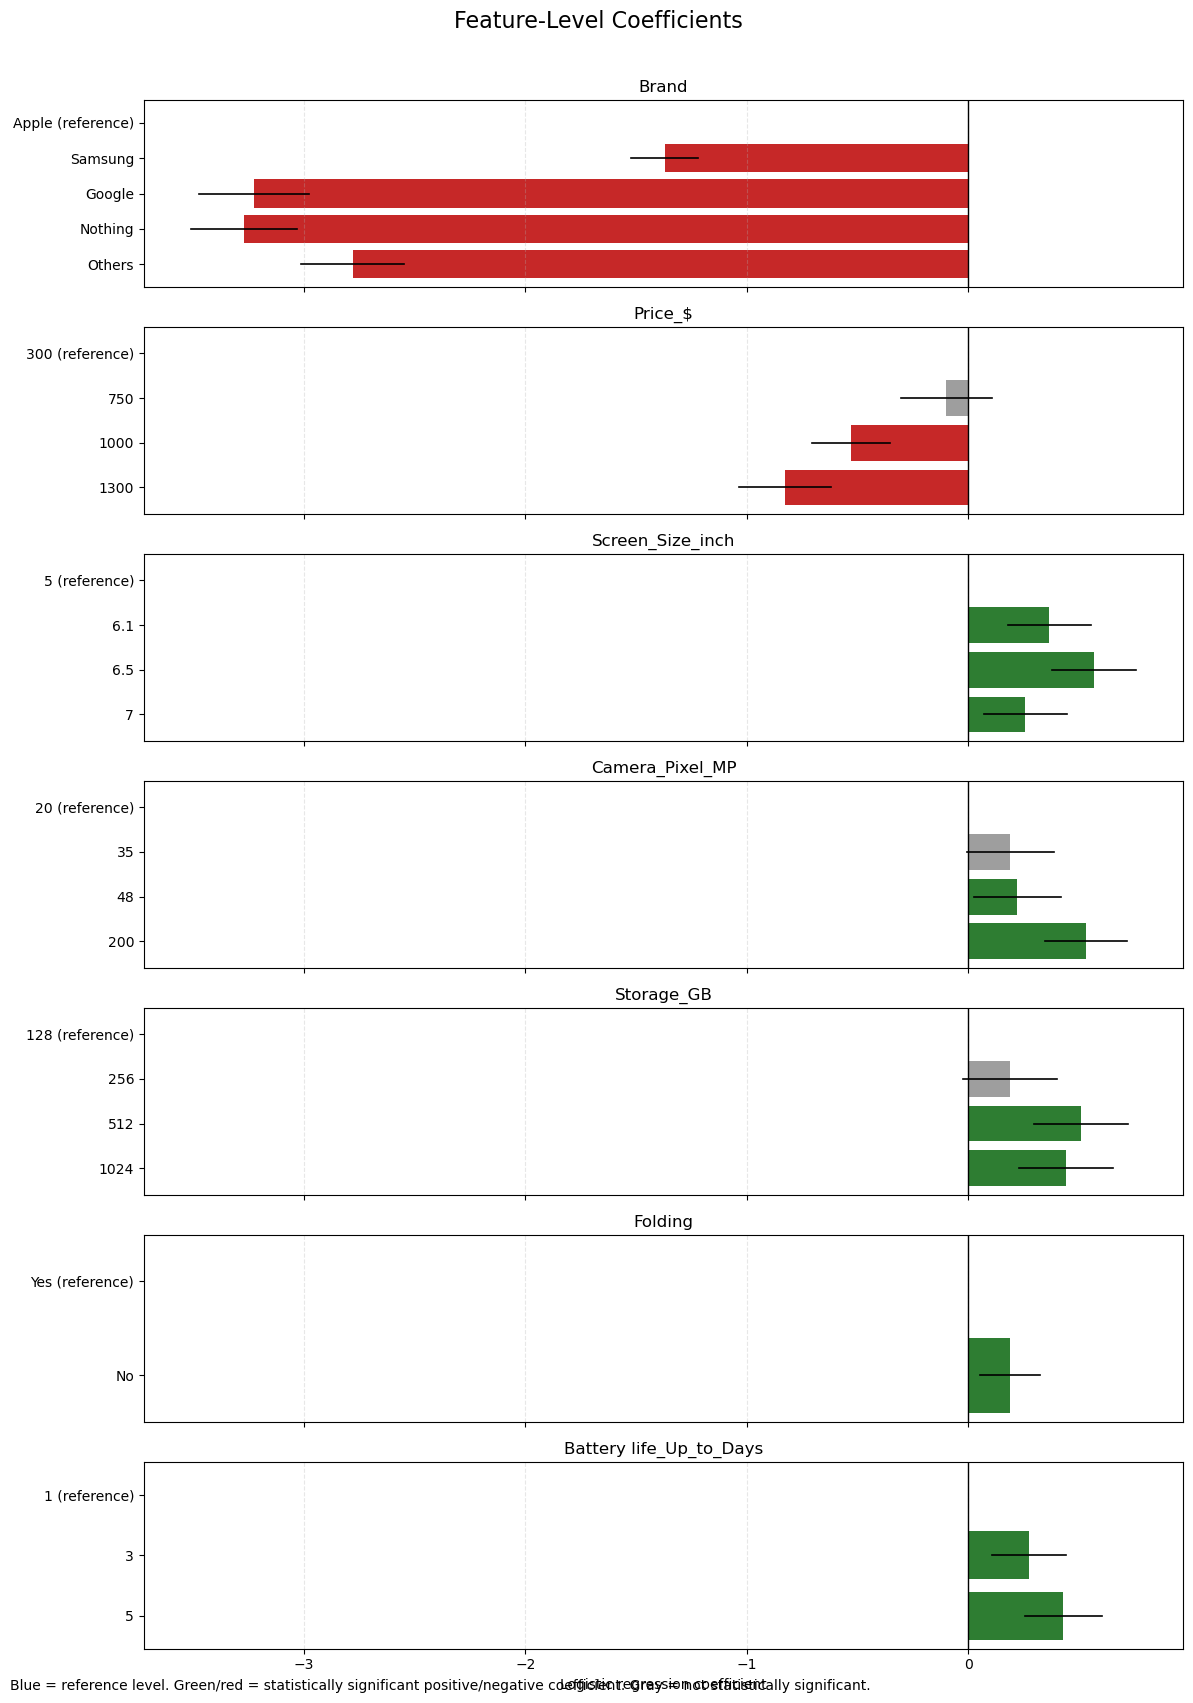

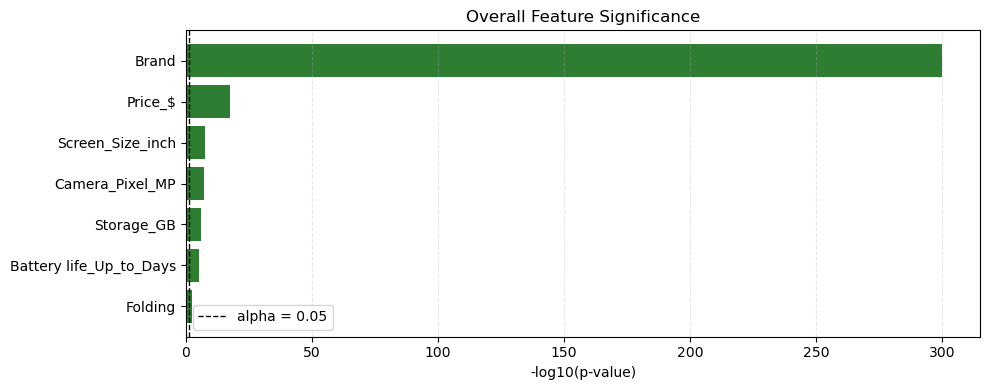

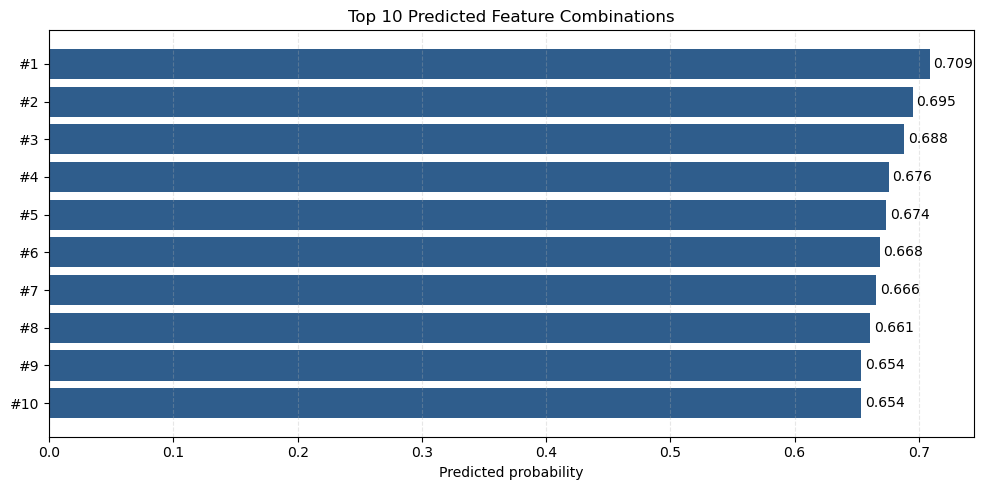

Saved coefficient plot to: /Users/semco/Documents/New project/Forecasting_package/outputs/conjoint_coefficients_by_feature.png
Saved feature p-value plot to: /Users/semco/Documents/New project/Forecasting_package/outputs/conjoint_feature_p_values.png
Saved top combinations plot to: /Users/semco/Documents/New project/Forecasting_package/outputs/conjoint_top_combinations.png
Saved optimum combination table to: /Users/semco/Documents/New project/Forecasting_package/outputs/conjoint_optimum_combination_long.csv

Most optimum product feature-level combination
Predicted probability: 0.708872
Predicted odds: 2.434912


,feature,optimum_level,predicted_probability_for_combination,predicted_odds_for_combination
0,Brand,Apple,0.708872,2.434912
1,Price_$,300,0.708872,2.434912
2,Screen_Size_inch,6.5,0.708872,2.434912
3,Camera_Pixel_MP,200,0.708872,2.434912
4,Storage_GB,512,0.708872,2.434912
5,Folding,No,0.708872,2.434912
6,Battery life_Up_to_Days,5,0.708872,2.434912



Top predicted product combinations with details


,combination_number,predicted_probability,predicted_odds,combination_details
0,#1,0.708872,2.434912,Brand: Apple | Price_$: 300 | Screen_Size_inch...
1,#2,0.694928,2.277913,Brand: Apple | Price_$: 300 | Screen_Size_inch...
2,#3,0.688182,2.206999,Brand: Apple | Price_$: 750 | Screen_Size_inch...
3,#4,0.675716,2.083712,Brand: Apple | Price_$: 300 | Screen_Size_inch...
4,#5,0.673703,2.064695,Brand: Apple | Price_$: 750 | Screen_Size_inch...
5,#6,0.668461,2.016237,Brand: Apple | Price_$: 300 | Screen_Size_inch...
6,#7,0.665583,1.990275,Brand: Apple | Price_$: 300 | Screen_Size_inch...
7,#8,0.660943,1.949358,Brand: Apple | Price_$: 300 | Screen_Size_inch...
8,#9,0.653820,1.888672,Brand: Apple | Price_$: 750 | Screen_Size_inch...
9,#10,0.653528,1.886234,Brand: Apple | Price_$: 300 | Screen_Size_inch...


In [5]:
# -----------------------------
# Visual results and optimum product feature combination
# -----------------------------

# Colors used in the coefficient plot.
REFERENCE_COLOR = "#2F5D8C"
POSITIVE_SIGNIFICANT_COLOR = "#2E7D32"
NEGATIVE_SIGNIFICANT_COLOR = "#C62828"
NOT_SIGNIFICANT_COLOR = "#9E9E9E"


def coefficient_color(row):
    if row["is_reference"]:
        return REFERENCE_COLOR
    if not row["significant"]:
        return NOT_SIGNIFICANT_COLOR
    if row["coefficient"] >= 0:
        return POSITIVE_SIGNIFICANT_COLOR
    return NEGATIVE_SIGNIFICANT_COLOR


# 1. Plot coefficients for every feature and level.
# Reference levels are shown at coefficient 0.
coefficient_plot_df = coefficients_df.copy()
coefficient_plot_df["plot_label"] = coefficient_plot_df.apply(
    lambda row: f"{row['level']}" + (" (reference)" if row["is_reference"] else ""),
    axis=1,
)

features_in_order = [spec.name for spec in analysis_specs]
fig_height = max(4, 2.4 * len(features_in_order))
fig, axes = plt.subplots(
    nrows=len(features_in_order),
    ncols=1,
    figsize=(12, fig_height),
    sharex=True,
)
if len(features_in_order) == 1:
    axes = [axes]

for ax, feature in zip(axes, features_in_order):
    feature_df = coefficient_plot_df.loc[coefficient_plot_df["feature"] == feature].copy()
    y_positions = np.arange(len(feature_df))
    colors = [coefficient_color(row) for _, row in feature_df.iterrows()]

    ax.barh(y_positions, feature_df["coefficient"], color=colors)

    # Add confidence intervals for non-reference levels.
    for y, (_, row) in zip(y_positions, feature_df.iterrows()):
        if not row["is_reference"] and not pd.isna(row["ci_lower"]):
            ax.plot([row["ci_lower"], row["ci_upper"]], [y, y], color="black", linewidth=1.2)

    ax.axvline(0, color="black", linewidth=1)
    ax.set_yticks(y_positions)
    ax.set_yticklabels(feature_df["plot_label"])
    ax.invert_yaxis()
    ax.set_title(feature)
    ax.grid(axis="x", linestyle="--", alpha=0.3)

axes[-1].set_xlabel("Logistic regression coefficient")
fig.suptitle("Feature-Level Coefficients", fontsize=16, y=1.01)
fig.text(
    0.01,
    0.01,
    "Blue = reference level. Green/red = statistically significant positive/negative coefficient. Gray = not statistically significant.",
    fontsize=10,
)
fig.tight_layout()
coefficient_plot_path = CONJOINT_OUTPUT_DIR / "conjoint_coefficients_by_feature.png"
fig.savefig(coefficient_plot_path, dpi=200, bbox_inches="tight")
plt.show()


# 2. Plot feature-level p-values from the joint Wald tests.
feature_pvalue_plot_df = feature_significance_df.copy().sort_values("p_value", ascending=True)
feature_pvalue_plot_df["minus_log10_p"] = -np.log10(feature_pvalue_plot_df["p_value"].clip(lower=1e-300))
significance_line = -np.log10(ALPHA)

fig, ax = plt.subplots(figsize=(10, max(4, 0.55 * len(feature_pvalue_plot_df))))
bar_colors = np.where(feature_pvalue_plot_df["significant"], POSITIVE_SIGNIFICANT_COLOR, NOT_SIGNIFICANT_COLOR)
ax.barh(feature_pvalue_plot_df["feature"], feature_pvalue_plot_df["minus_log10_p"], color=bar_colors)
ax.axvline(significance_line, color="black", linestyle="--", linewidth=1, label=f"alpha = {ALPHA}")
ax.invert_yaxis()
ax.set_xlabel("-log10(p-value)")
ax.set_title("Overall Feature Significance")
ax.legend()
ax.grid(axis="x", linestyle="--", alpha=0.3)
fig.tight_layout()
feature_pvalue_plot_path = CONJOINT_OUTPUT_DIR / "conjoint_feature_p_values.png"
fig.savefig(feature_pvalue_plot_path, dpi=200, bbox_inches="tight")
plt.show()


# 3. Create a readable label for each top predicted combination.
def combination_label(row, specs):
    pieces = []
    for spec in specs:
        pieces.append(f"{spec.name}: {row[spec.name]}")
    return " | ".join(pieces)


top_plot_df = top_combinations_df.head(TOP_N_COMBINATIONS).copy()
top_plot_df["combination_number"] = [f"#{i}" for i in range(1, len(top_plot_df) + 1)]
top_plot_df["combination_details"] = top_plot_df.apply(
    lambda row: combination_label(row, analysis_specs),
    axis=1,
)

fig, ax = plt.subplots(figsize=(10, max(4, 0.5 * len(top_plot_df))))
ax.barh(top_plot_df["combination_number"], top_plot_df["predicted_probability"], color="#2F5D8C")
ax.invert_yaxis()
ax.set_xlabel("Predicted probability")
ax.set_title(f"Top {TOP_N_COMBINATIONS} Predicted Feature Combinations")
ax.grid(axis="x", linestyle="--", alpha=0.3)
for y, probability in enumerate(top_plot_df["predicted_probability"]):
    ax.text(probability + 0.003, y, f"{probability:.3f}", va="center")
fig.tight_layout()
top_combinations_plot_path = CONJOINT_OUTPUT_DIR / "conjoint_top_combinations.png"
fig.savefig(top_combinations_plot_path, dpi=200, bbox_inches="tight")
plt.show()


# 4. Output the single optimum product feature-level combination in a beginner-friendly format.
best_row = best_combination_df.iloc[0]
optimum_combination_df = pd.DataFrame([
    {
        "feature": spec.name,
        "optimum_level": best_row[spec.name],
        "predicted_probability_for_combination": best_row["predicted_probability"],
        "predicted_odds_for_combination": best_row["predicted_odds"],
    }
    for spec in analysis_specs
])

optimum_combination_path = CONJOINT_OUTPUT_DIR / "conjoint_optimum_combination_long.csv"
optimum_combination_df.to_csv(optimum_combination_path, index=False)

print("Saved coefficient plot to:", coefficient_plot_path)
print("Saved feature p-value plot to:", feature_pvalue_plot_path)
print("Saved top combinations plot to:", top_combinations_plot_path)
print("Saved optimum combination table to:", optimum_combination_path)

print("\nMost optimum product feature-level combination")
print(f"Predicted probability: {best_row['predicted_probability']:.6f}")
print(f"Predicted odds: {best_row['predicted_odds']:.6f}")
display(optimum_combination_df)

print("\nTop predicted product combinations with details")
display(top_plot_df[["combination_number", "predicted_probability", "predicted_odds", "combination_details"]])

## Cell 6: Nothing Brand Scenario Purchase Probability

Run this cell after the conjoint model cell. It reads `Forecasting_Model_Spec.csv` and predicts purchase probability for every scenario row using the logistic regression model from Cell 4.

Beginner notes:

- The model can predict new scenario/profile combinations that were not shown in the fractional factorial design.
- Categorical feature values, such as `Brand`, should use categories that exist in `levels_used.csv` because the model has not learned coefficients for brand-new category names.
- Numeric feature values can be exact listed values or values between listed values. When a numeric value falls between listed levels, this cell interpolates between the two nearby learned level effects for prediction.
- To forecast only one brand's rows, set `SCENARIO_BRAND_FILTER` at the top of the forecasting code (for example `"Nothing"`). The default `None` forecasts every row.
- The chart at the end gives a visual comparison of predicted purchase probability for each scenario.


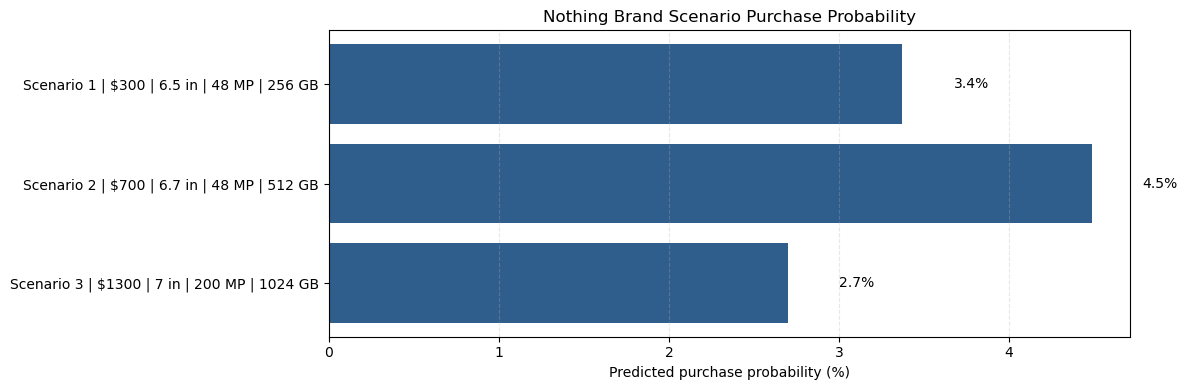

Nothing brand scenario purchase-probability forecast complete
Saved scenario predictions to: /Users/semco/Documents/New project/Forecasting_package/outputs/nothing_brand_scenario_predictions.csv
Saved scenario value-handling table to: /Users/semco/Documents/New project/Forecasting_package/outputs/nothing_brand_scenario_level_mapping.csv
Saved purchase-probability chart to: /Users/semco/Documents/New project/Forecasting_package/outputs/nothing_brand_scenario_purchase_probability.png

Scenario values that were interpolated or otherwise adjusted


,scenario_label,feature,original_value,model_input,handling,note
8,Scenario 2,Price_$,700,300 (0.111) | 750 (0.889),interpolated numeric value,Price_$: 700 interpolated between 300 and 750
9,Scenario 2,Screen_Size_inch,6.7,6.5 (0.600) | 7 (0.400),interpolated numeric value,Screen_Size_inch: 6.7 interpolated between 6.5...



Nothing brand scenario predictions


,scenario_id,scenario_label,Brand,Price_$,Screen_Size_inch,Camera_Pixel_MP,Storage_GB,Folding,Battery life_Up_to_Days,predicted_purchase_probability,predicted_purchase_probability_percent
0,1,Scenario 1,Nothing,300,6.5,48,256,Yes,3,0.033721,3.372145
1,2,Scenario 2,Nothing,700,6.7,48,512,No,3,0.044847,4.484679
2,3,Scenario 3,Nothing,1300,7,200,1024,No,5,0.026999,2.699935


In [6]:
# -----------------------------
# Nothing brand scenario purchase-probability forecast
# -----------------------------


def scenario_label(row, index):
    """Use Phone Model when available; otherwise create an easy scenario name."""
    for column in ["Phone Model", "Model", "Scenario", "Scenario Name"]:
        if column in row.index:
            value = str(row[column]).strip()
            if value and value.lower() != "nan":
                return value
    return f"Scenario {index + 1}"


def format_numeric_value(value):
    numeric_value = float(value)
    return str(int(numeric_value)) if numeric_value.is_integer() else str(round(numeric_value, 6))


def format_weighted_levels(weights):
    """Create a readable description of exact or interpolated level weights."""
    if len(weights) == 1:
        return next(iter(weights.keys()))
    return " | ".join(f"{level} ({weight:.3f})" for level, weight in weights.items())


def scenario_value_weights_for_prediction(value, spec):
    """
    Prepare one scenario value for model prediction.

    New scenario combinations are allowed. For numeric values not listed exactly in
    levels_used.csv, the code interpolates between nearby learned level effects.
    For categorical values, the category must already exist in levels_used.csv.
    """
    if pd.isna(value) or str(value).strip() == "":
        raise ValueError(f"Missing value for {spec.name!r} in Forecasting_Model_Spec.csv.")

    original_value = str(value).strip()
    normalized_value = normalize_level(value, spec.kind)

    if spec.kind in {"continuous", "discrete"}:
        numeric_value = float(original_value)
        display_value = format_numeric_value(numeric_value)
        level_pairs = sorted((float(level), level) for level in spec.levels)

        for level_number, level_label in level_pairs:
            if np.isclose(numeric_value, level_number):
                weights = {level_label: 1.0}
                return display_value, weights, "exact listed numeric value", format_weighted_levels(weights), ""

        smallest_value, smallest_label = level_pairs[0]
        largest_value, largest_label = level_pairs[-1]

        if numeric_value < smallest_value:
            weights = {smallest_label: 1.0}
            note = f"{spec.name}: {original_value} is below the listed range; {smallest_label} used for prediction"
            return display_value, weights, "nearest boundary numeric value", format_weighted_levels(weights), note

        if numeric_value > largest_value:
            weights = {largest_label: 1.0}
            note = f"{spec.name}: {original_value} is above the listed range; {largest_label} used for prediction"
            return display_value, weights, "nearest boundary numeric value", format_weighted_levels(weights), note

        for (lower_value, lower_label), (upper_value, upper_label) in zip(level_pairs[:-1], level_pairs[1:]):
            if lower_value <= numeric_value <= upper_value:
                upper_weight = (numeric_value - lower_value) / (upper_value - lower_value)
                lower_weight = 1.0 - upper_weight
                weights = {lower_label: lower_weight, upper_label: upper_weight}
                note = (
                    f"{spec.name}: {original_value} interpolated between "
                    f"{lower_label} and {upper_label}"
                )
                return display_value, weights, "interpolated numeric value", format_weighted_levels(weights), note

    if normalized_value in spec.levels:
        weights = {normalized_value: 1.0}
        return normalized_value, weights, "exact listed categorical value", format_weighted_levels(weights), ""

    lower_to_level = {str(level).strip().lower(): level for level in spec.levels}
    matched_level = lower_to_level.get(normalized_value.lower())
    if matched_level is not None:
        weights = {matched_level: 1.0}
        note = f"{spec.name}: {original_value} matched to listed category {matched_level}"
        return matched_level, weights, "case-insensitive categorical match", format_weighted_levels(weights), note

    allowed = ", ".join(spec.levels)
    raise ValueError(
        f"The model can predict new scenario combinations, but categorical feature {spec.name!r} "
        f"has value {original_value!r}, which is not in the learned category list. "
        f"Allowed categories: {allowed}"
    )


def prepare_forecasting_scenarios(raw_scenarios_df, specs):
    """Return scenario rows, value-handling notes, and model encoding weights."""
    forecast_rows = []
    value_handling_rows = []
    scenario_weight_rows = []

    for row_index, row in enumerate(raw_scenarios_df.to_dict("records")):
        row_series = pd.Series(row)
        scenario_name = scenario_label(row_series, row_index)
        forecast_row = {"scenario_id": row_index + 1, "scenario_label": scenario_name}
        feature_weights = {}

        for spec in specs:
            if spec.name not in raw_scenarios_df.columns:
                raise ValueError(
                    f"Forecasting_Model_Spec.csv is missing required feature column {spec.name!r}."
                )

            original_value = row[spec.name]
            display_value, weights, handling, model_input, note = scenario_value_weights_for_prediction(
                original_value,
                spec,
            )
            forecast_row[spec.name] = display_value
            feature_weights[spec.name] = weights
            value_handling_rows.append({
                "scenario_id": row_index + 1,
                "scenario_label": scenario_name,
                "feature": spec.name,
                "original_value": original_value,
                "value_shown_in_prediction_table": display_value,
                "model_input": model_input,
                "handling": handling,
                "note": note,
            })

        forecast_rows.append(forecast_row)
        scenario_weight_rows.append(feature_weights)

    return pd.DataFrame(forecast_rows), pd.DataFrame(value_handling_rows), scenario_weight_rows


def encode_forecasting_scenarios(scenarios_df, scenario_weight_rows, specs, model_columns):
    """
    Create the model matrix for new scenarios.

    Exact listed levels use the same indicator coding as the training data.
    Interpolated numeric values split their weight across the two nearby level indicators.
    """
    encoded_df = scenarios_df.copy()

    for column in model_columns:
        encoded_df[column] = 0.0

    for row_position, feature_weights in enumerate(scenario_weight_rows):
        row_label = encoded_df.index[row_position]
        for spec in specs:
            for level, weight in feature_weights[spec.name].items():
                if level == spec.levels[0]:
                    continue
                column = indicator_name(spec.name, level)
                if column in encoded_df.columns:
                    encoded_df.loc[row_label, column] = float(weight)

    return encoded_df


def predict_with_logistic_model(encoded_scenarios_df, result, model_columns):
    x = sm.add_constant(encoded_scenarios_df[model_columns].astype(float), has_constant="add")
    x = x.reindex(columns=result.params.index, fill_value=0.0)
    return np.asarray(result.predict(x), dtype=float)


# Optional: set to a brand name (for example "Nothing") to forecast only that brand's rows.
# Leave as None to forecast every scenario row in Forecasting_Model_Spec.csv.
SCENARIO_BRAND_FILTER = None

forecasting_raw_df = read_csv(FORECASTING_MODEL_SPEC_PATH)

if SCENARIO_BRAND_FILTER is not None and "Brand" in forecasting_raw_df.columns:
    brand_mask = (
        forecasting_raw_df["Brand"].astype(str).str.strip().str.lower()
        == str(SCENARIO_BRAND_FILTER).strip().lower()
    )
    skipped_rows = int((~brand_mask).sum())
    if skipped_rows:
        print(f"Skipping {skipped_rows} scenario row(s) whose Brand is not {SCENARIO_BRAND_FILTER!r}.")
    forecasting_raw_df = forecasting_raw_df.loc[brand_mask].copy()

if forecasting_raw_df.empty:
    raise ValueError("Forecasting_Model_Spec.csv does not contain any scenario rows to forecast.")

forecasting_scenarios_df, scenario_value_handling_df, scenario_weight_rows = prepare_forecasting_scenarios(
    forecasting_raw_df,
    analysis_specs,
)
encoded_forecasting_scenarios_df = encode_forecasting_scenarios(
    forecasting_scenarios_df,
    scenario_weight_rows,
    analysis_specs,
    model_columns,
)

scenario_purchase_probability = predict_with_logistic_model(
    encoded_forecasting_scenarios_df,
    logistic_result,
    model_columns,
)

scenario_predictions_df = forecasting_scenarios_df.copy()
scenario_predictions_df["predicted_purchase_probability"] = scenario_purchase_probability
scenario_predictions_df["predicted_purchase_probability_percent"] = (
    scenario_predictions_df["predicted_purchase_probability"] * 100
)

# Save the forecast outputs.
scenario_predictions_path = CONJOINT_OUTPUT_DIR / "nothing_brand_scenario_predictions.csv"
scenario_value_handling_path = CONJOINT_OUTPUT_DIR / "nothing_brand_scenario_level_mapping.csv"

scenario_predictions_df.to_csv(scenario_predictions_path, index=False)
scenario_value_handling_df.to_csv(scenario_value_handling_path, index=False)

# Visual: purchase probability by scenario.
plot_df = scenario_predictions_df.copy()
plot_df["plot_label"] = plot_df.apply(
    lambda row: (
        f"{row['scenario_label']} | ${row['Price_$']} | {row['Screen_Size_inch']} in | "
        f"{row['Camera_Pixel_MP']} MP | {row['Storage_GB']} GB"
    ),
    axis=1,
)

fig, ax = plt.subplots(figsize=(12, max(4, 0.7 * len(plot_df))))
ax.barh(plot_df["plot_label"], plot_df["predicted_purchase_probability_percent"], color="#2F5D8C")
ax.invert_yaxis()
ax.set_xlabel("Predicted purchase probability (%)")
ax.set_title("Nothing Brand Scenario Purchase Probability")
ax.grid(axis="x", linestyle="--", alpha=0.3)
for y_position, probability_percent in enumerate(plot_df["predicted_purchase_probability_percent"]):
    ax.text(probability_percent + 0.3, y_position, f"{probability_percent:.1f}%", va="center")
fig.tight_layout()
purchase_probability_plot_path = CONJOINT_OUTPUT_DIR / "nothing_brand_scenario_purchase_probability.png"
fig.savefig(purchase_probability_plot_path, dpi=200, bbox_inches="tight")
plt.show()

print("Nothing brand scenario purchase-probability forecast complete")
print(f"Saved scenario predictions to: {scenario_predictions_path}")
print(f"Saved scenario value-handling table to: {scenario_value_handling_path}")
print(f"Saved purchase-probability chart to: {purchase_probability_plot_path}")

non_exact_handling_df = scenario_value_handling_df.loc[
    ~scenario_value_handling_df["handling"].str.startswith("exact listed")
]
print("\nScenario values that were interpolated or otherwise adjusted")
if non_exact_handling_df.empty:
    print("All scenario values exactly matched listed model levels.")
else:
    display(non_exact_handling_df[[
        "scenario_label",
        "feature",
        "original_value",
        "model_input",
        "handling",
        "note",
    ]])

print("\nNothing brand scenario predictions")
display(scenario_predictions_df)


## What to Download or Share

After running the notebook, the most important output files are:

- `fractional_factorial_design.csv`: the product profiles used in the conjoint survey
- `levels_used.csv`: the exact feature levels used by the design and model
- `outputs/conjoint_model_dataset.csv`: the survey response data reshaped for modeling
- `outputs/conjoint_model_metrics.csv`: model R2, p-value, and fit statistics
- `outputs/conjoint_feature_significance.csv`: p-values for each feature
- `outputs/conjoint_coefficients.csv`: coefficient and odds-ratio output for every feature level
- `outputs/conjoint_best_combination.csv`: the single highest-probability feature combination
- `outputs/conjoint_top_combinations.csv`: the top predicted feature combinations
- `outputs/conjoint_coefficients_by_feature.png`: visual coefficient summary
- `outputs/conjoint_feature_p_values.png`: visual feature-significance summary
- `outputs/conjoint_top_combinations.png`: visual top-combination summary
- `Forecasting_Model_Spec.csv`: the Nothing-brand scenario profiles to forecast, including new combinations not shown in the design
- `outputs/nothing_brand_scenario_predictions.csv`: purchase probability for each Nothing scenario
- `outputs/nothing_brand_scenario_level_mapping.csv`: how each scenario value was used for prediction, including any numeric interpolation
- `outputs/nothing_brand_scenario_purchase_probability.png`: visual purchase probability by scenario

To share this package with another user, keep the notebook, CSV files, `requirements.txt`, and this `outputs` folder together inside the same `Forecasting_package` folder.
